# Compound Heat-Drought Stress over India -- Mid-Eval Demo

Loads only cached outputs from `data/processed/` and `results/` -- no
network calls, so this runs in well under a minute and can't fail on a
flaky connection during the live demo.

Run `scripts/00`-`06` first to populate those caches from real data.

In [1]:
import sys
from pathlib import Path

# Find the midSub folder (the one containing chd/) no matter where Jupyter was started
_here = Path.cwd().resolve()
_candidates = [_here, *_here.parents] + [p / "midSub" for p in [_here, *_here.parents]]
PROJECT_ROOT = next((p for p in _candidates if (p / "chd" / "config.py").exists()), None)
if PROJECT_ROOT is None:
    raise RuntimeError(f"Can't find the midSub folder (with chd/) from {_here}. "
                       "Open the notebook from inside the midSub folder.")
sys.path.insert(0, str(PROJECT_ROOT))
print("Project folder:", PROJECT_ROOT)
print("Python running this notebook:", sys.executable)

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Image
from matplotlib.colors import ListedColormap

from chd import config as cfg
from chd.plotting import CATEGORY_COLORS, CATEGORY_ORDER

CUBE_AVAILABLE = cfg.CUBE_PATH.exists()
EVENTS_AVAILABLE = cfg.EVENTS_PATH.exists()
print(f"cube.nc available: {CUBE_AVAILABLE}")
print(f"events.csv available: {EVENTS_AVAILABLE}")

if CUBE_AVAILABLE:
    ds = xr.open_dataset(cfg.CUBE_PATH)
    print(ds)
else:
    ds = None
    print("Run scripts/00-02 first to generate the cube. "
          "The rest of this notebook will show placeholders until then.")

Project folder: C:\Users\choud\OneDrive\Desktop\NewCollegeDocs\4-1\EST\midSub
Python running this notebook: C:\Users\choud\venvs\est-midsub\Scripts\python.exe


cube.nc available: True
events.csv available: True


<xarray.Dataset> Size: 1GB
Dimensions:           (time: 264, lat: 126, lon: 120, era5_time: 408, month: 12)
Coordinates:
  * time              (time) datetime64[ns] 2kB 2001-01-01 ... 2022-12-01
  * lat               (lat) float64 1kB 37.38 37.12 36.88 ... 6.625 6.375 6.125
  * lon               (lon) float64 960B 68.12 68.38 68.62 ... 97.38 97.62 97.88
  * era5_time         (era5_time) datetime64[ns] 3kB 1991-01-01 ... 2024-12-01
  * month             (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
Data variables: (12/39)
    tmax_c            (time, lat, lon) float64 32MB ...
    t2m_c             (time, lat, lon) float64 32MB ...
    dewpoint_c        (time, lat, lon) float64 32MB ...
    swvl1             (time, lat, lon) float64 32MB ...
    swvl2             (time, lat, lon) float64 32MB ...
    swvl3             (time, lat, lon) float64 32MB ...
    ...                ...
    category_full     (era5_time, lat, lon) <U8 197MB ...
    gpp_z             (time, lat, lon) float64 32MB .

## 1. Month picker: map of Tz / SPEI / category / GPP z

In [2]:
def plot_month(year, month):
    if ds is None:
        print("No cube loaded.")
        return
    sel = ds.sel(time=f"{year}-{month:02d}-01", method="nearest")
    india_mask = ds["is_india"].values if "is_india" in ds else None

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    extent = [float(ds.lon.min()), float(ds.lon.max()), float(ds.lat.min()), float(ds.lat.max())]
    fields = [
        ("tmax_z", "Reds", -2, 3, "Tmax z"),
        ("spei03", "BrBG", -2.5, 2.5, "SPEI-3"),
        ("gpp_z", "RdYlGn", -3, 3, "GPP z"),
    ]
    for ax, (var, cmap, vmin, vmax, label) in zip(axes[:3], fields):
        field = sel[var].values
        if india_mask is not None:
            field = np.where(india_mask, field, np.nan)
        im = ax.imshow(field, cmap=cmap, vmin=vmin, vmax=vmax, origin="upper", extent=extent)
        ax.set_title(label)
        fig.colorbar(im, ax=ax, shrink=0.7)

    cat_codes = {"normal": 0, "hot_only": 1, "dry_only": 2, "compound": 3, "nan": -1}
    coded = np.vectorize(lambda c: cat_codes.get(c, -1))(sel["category"].values).astype(float)
    coded[coded < 0] = np.nan
    if india_mask is not None:
        coded = np.where(india_mask, coded, np.nan)
    # exactly four colours, same as the slides (blue/orange/red/green)
    cmap4 = ListedColormap([CATEGORY_COLORS[c] for c in CATEGORY_ORDER])
    im = axes[3].imshow(coded, cmap=cmap4, vmin=-0.5, vmax=3.5, origin="upper", extent=extent)
    axes[3].set_title("Category")
    cbar = fig.colorbar(im, ax=axes[3], ticks=[0, 1, 2, 3], shrink=0.7)
    cbar.ax.set_yticklabels(["normal", "hot", "dry", "compound"])

    fig.suptitle(f"{year}-{month:02d}")
    fig.tight_layout()
    plt.show()


if ds is not None:
    years = sorted(set(pd.DatetimeIndex(ds["time"].values).year))
    widgets.interact(plot_month,
                      year=widgets.IntSlider(min=min(years), max=max(years), value=2009),
                      month=widgets.IntSlider(min=1, max=12, value=7))
else:
    print("(interactive map picker disabled -- no cube loaded)")

interactive(children=(IntSlider(value=2009, description='year', max=2022, min=2001), IntSlider(value=7, descri…

## 2. Cell picker: time series at three preset locations

- Western Ghats (evergreen forest): ~10.5N, 76.5E
- Central India (deciduous forest): ~21.5N, 80.5E
- Punjab (irrigated cropland): ~30.5N, 75.5E

In [3]:
PRESETS = {
    "Western Ghats (evergreen)": (10.5, 76.5),
    "Central India (deciduous)": (21.5, 80.5),
    "Punjab (irrigated cropland)": (30.5, 75.5),
}

def plot_cell_series(site_name):
    if ds is None:
        print("No cube loaded.")
        return
    lat, lon = PRESETS[site_name]
    cell = ds.sel(lat=lat, lon=lon, method="nearest")
    dates = pd.DatetimeIndex(cell["time"].values)

    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.plot(dates, cell["gpp_z"].values, label="GPP z", color="#2a7")
    ax.axhline(0, color="gray", linewidth=0.6)

    cats = cell["category"].values
    for cat, color in [("hot_only", "#DD8452"), ("dry_only", "#C44E52"), ("compound", "#55A868")]:
        mask = cats == cat
        ax.fill_between(dates, -3, 3, where=mask, color=color, alpha=0.15, step="mid", label=cat)

    ax.set_ylim(-3, 3)
    ax.set_title(f"{site_name} (lat={float(cell.lat):.2f}, lon={float(cell.lon):.2f})")
    ax.legend(loc="lower left", fontsize=8, ncol=2)
    fig.tight_layout()
    plt.show()


if ds is not None:
    widgets.interact(plot_cell_series, site_name=list(PRESETS.keys()))
else:
    print("(interactive cell picker disabled -- no cube loaded)")

interactive(children=(Dropdown(description='site_name', options=('Western Ghats (evergreen)', 'Central India (…

## 3. Headline results table

In [4]:
for name in ["composite_gpp_z_overall.csv", "composite_ndvi_z_overall.csv",
             "contrasts_gpp_z_overall.csv", "contrasts_ndvi_z_overall.csv",
             "robustness_spei_vs_spi.csv", "peninsular_vs_north_test.csv",
             "recovery_km.csv", "recovery_severity_matched.csv",
             "compound_area_trend_stats.csv"]:
    path = cfg.RESULTS / name
    print(f"--- {name} ---")
    if path.exists():
        display(pd.read_csv(path))
    else:
        print("  (not yet generated -- run the corresponding script)")
    print()

--- composite_gpp_z_overall.csv ---


,category,n,mean,ci_low,ci_high,flagged_low_n
0,compound,62265,-0.429075,-0.543127,-0.334519,False
1,dry_only,109073,-0.271619,-0.395983,-0.154352,False
2,hot_only,79717,-0.130309,-0.242229,-0.011890,False
3,normal,573543,0.116360,0.031484,0.192785,False



--- composite_ndvi_z_overall.csv ---


,category,n,mean,ci_low,ci_high,flagged_low_n
0,compound,56569,-0.681402,-0.813242,-0.550863,False
1,dry_only,94750,-0.301406,-0.408376,-0.213334,False
2,hot_only,70412,-0.370764,-0.504724,-0.255306,False
3,normal,480956,0.193817,0.110115,0.262428,False



--- contrasts_gpp_z_overall.csv ---


,n_normal,mean_normal,n_hot_only,mean_hot_only,n_dry_only,mean_dry_only,n_compound,mean_compound,d_hot,d_hot_ci_low,...,compound_minus_dry_sig,compound_minus_hot,compound_minus_hot_ci_low,compound_minus_hot_ci_high,compound_minus_hot_sig,amplification_index,amplification_index_ci_low,amplification_index_ci_high,amplification_index_sig,min_category_n
0,573543,0.11636,79717,-0.130309,109073,-0.271619,62265,-0.429075,-0.246669,-0.34118,...,True,-0.298767,-0.396748,-0.210278,True,0.089212,-0.030795,0.211557,False,62265


... (8 outputs left out)


--- recovery_severity_matched.csv ---


,severity_bin,event_type,n_events,median_severity,km_median_rt,p_recovered_by_12m,logrank_p_within_bin
0,T1,compound,6742,2.941088,4.0,0.979637,1.053288e-03
1,T1,drought_only,3737,2.713538,3.0,0.964190,1.053288e-03
2,T2,compound,8372,4.862734,4.0,0.989330,8.214782e-06
3,T2,drought_only,2105,4.514814,3.0,0.979868,8.214782e-06
4,T3,compound,9474,8.005045,3.0,0.987282,3.410207e-08
5,T3,drought_only,1005,7.712240,2.0,0.967456,3.410207e-08



--- compound_area_trend_stats.csv ---


,slope,intercept,slope_ci_low,slope_ci_high,tau,p_value,n
0,0.033076,-61.078738,-0.089539,0.164586,0.069519,0.563161,34


## 4. Response surface (Tmax-z x SPEI-3)

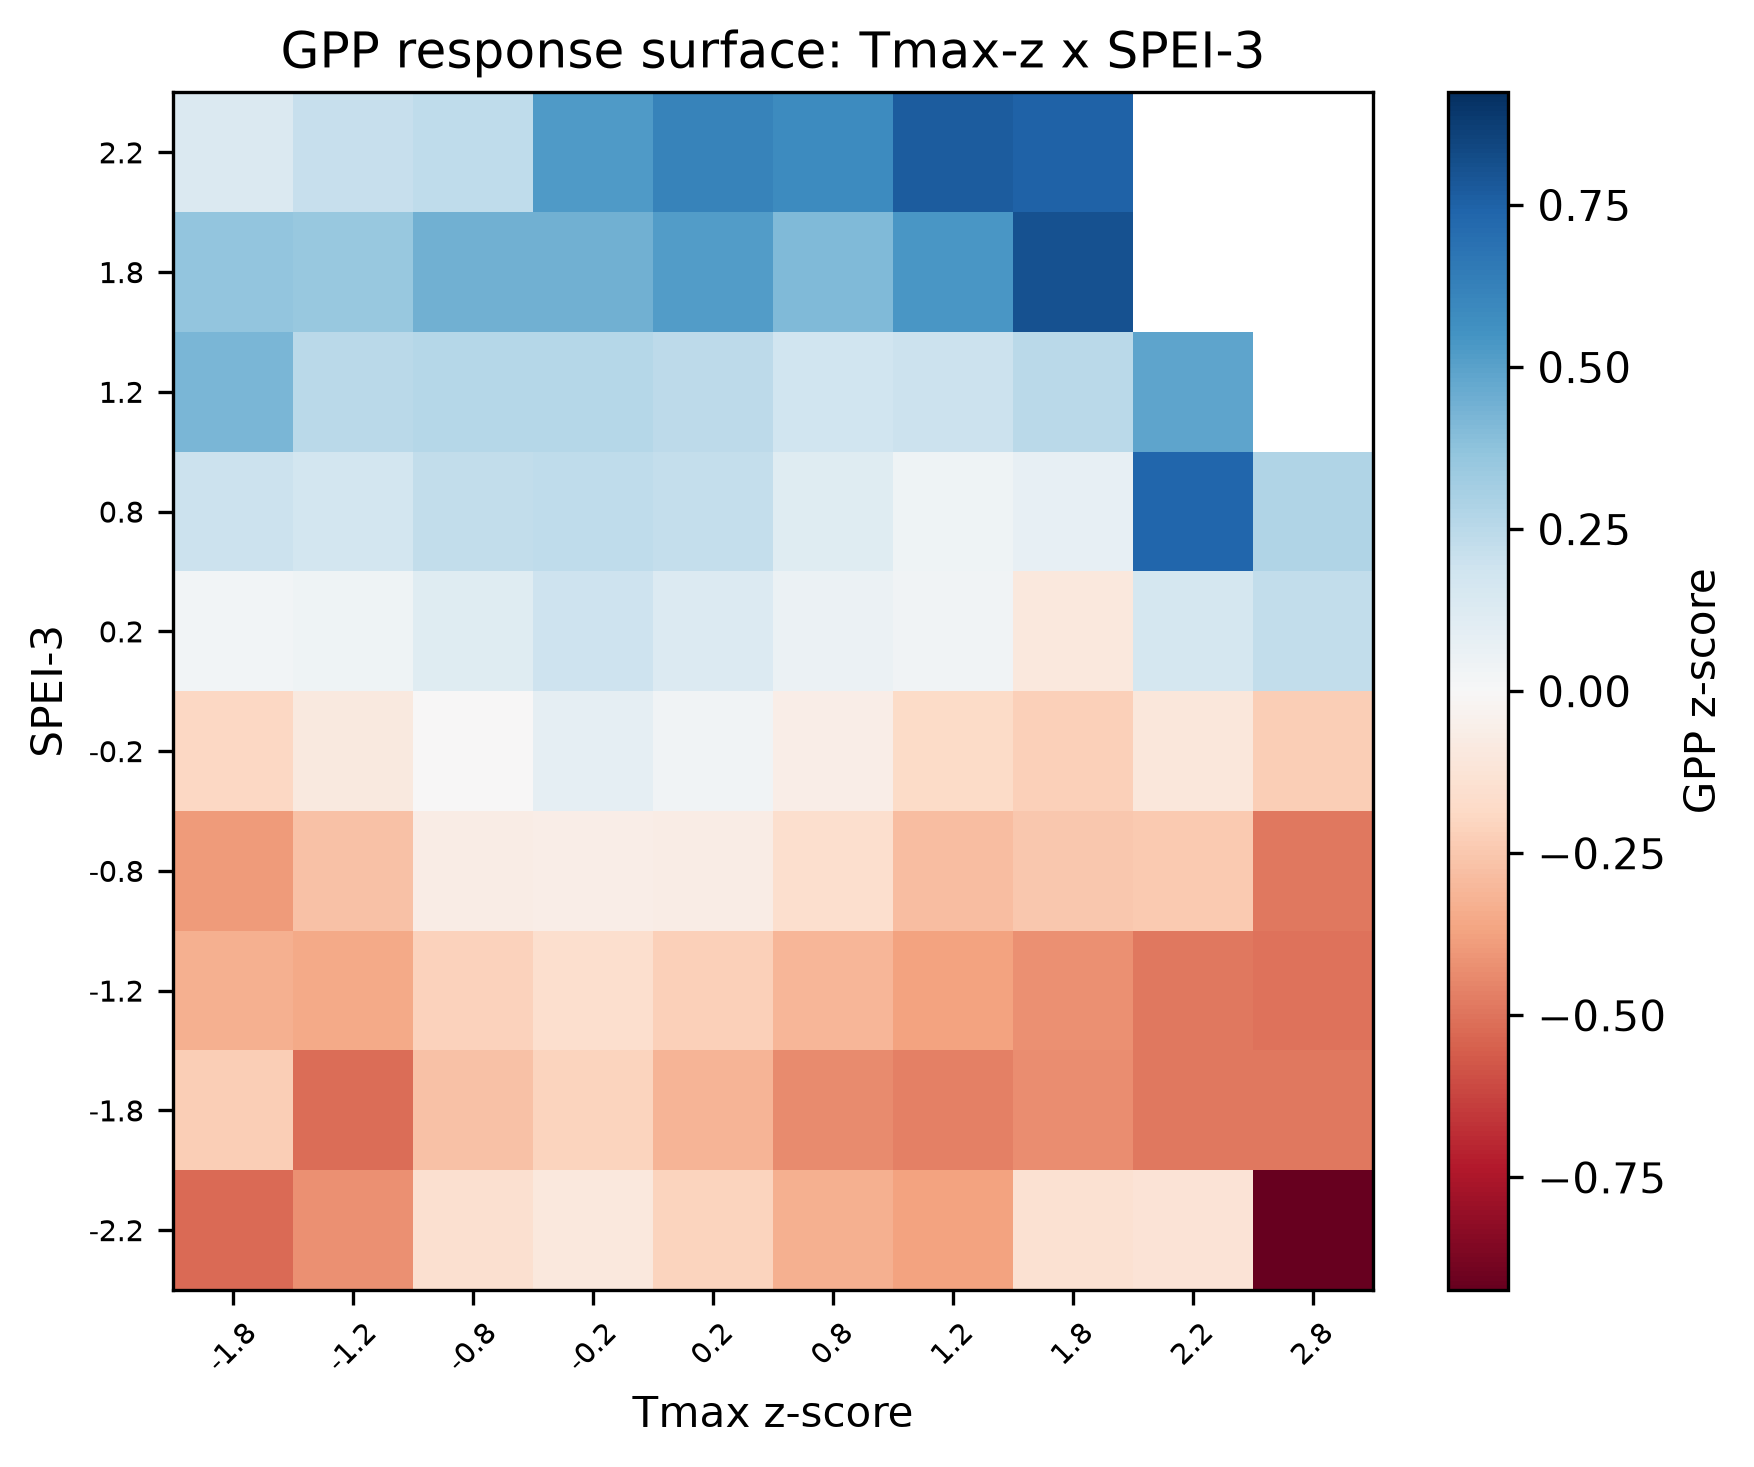

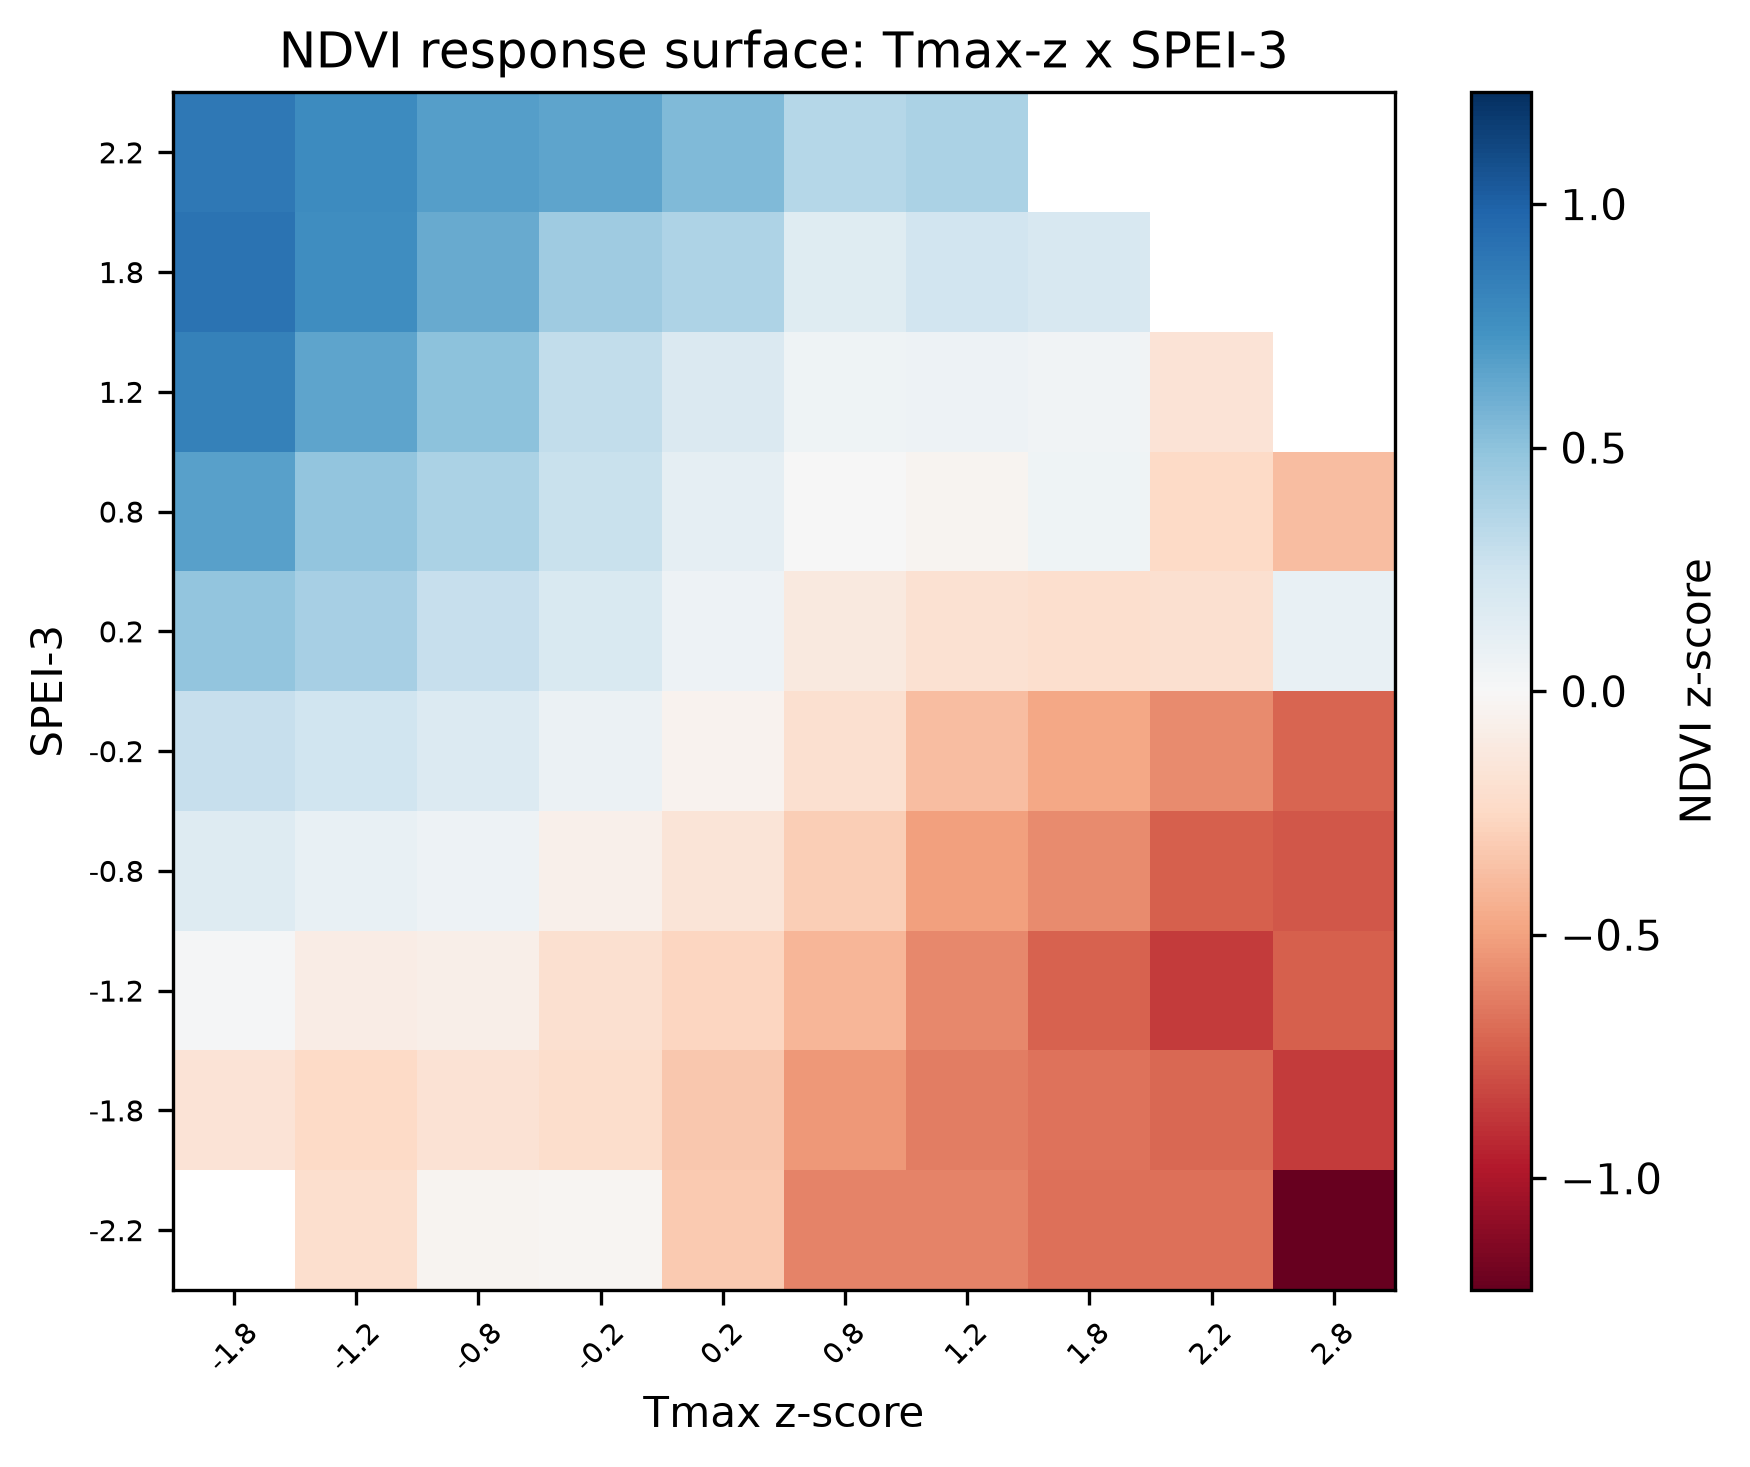

In [5]:
for stem in ["response_surface_gpp", "response_surface_ndvi"]:
    fig_path = cfg.FIGURES / f"{stem}.png"
    if fig_path.exists():
        display(Image(filename=str(fig_path), width=520))
    else:
        print(f"({stem}.png not yet generated -- run scripts/04_impacts.py)")

## 5. Optional: one live Earth Engine call

Disabled by default (`RUN_LIVE_EE_CHECK = False`). Flip it on only if you
want to demo a live GEE round-trip during the presentation -- it needs
`EE_PROJECT` set and network access.

In [6]:
RUN_LIVE_EE_CHECK = False

if RUN_LIVE_EE_CHECK:
    from chd.gee import init_ee
    ee = init_ee()
    img = ee.ImageCollection(cfg.MODIS_NDVI).filterDate("2020-07-01", "2020-08-01").first()
    print(img.getInfo()["bands"])
else:
    print("Live EE check skipped (RUN_LIVE_EE_CHECK = False).")

Live EE check skipped (RUN_LIVE_EE_CHECK = False).
